# Unemployment Analysis with Python

# 1. Import Libraries and Load the Dataset

In this section, we import the required Python libraries and load the unemployment dataset to analyze unemployment trends in India.



In [1]:
# Import pandas for working with tables of data
import pandas as pd

# Import matplotlib for creating graphs
import matplotlib.pyplot as plt

# Import seaborn for statistical visualizations
import seaborn as sns

# Set display options
pd.set_option("display.max_columns", None)

# Set the visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the unemployment dataset
df = pd.read_csv("Unemployment in India.csv")

# Display the first five rows
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display dataset information
print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (768, 7)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 66.1 KB

Missing values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unem

# 2. Data Cleaning and Preprocessing

In this section, we clean the dataset by removing unnecessary spaces from column names, converting data into appropriate formats, and handling missing values.


In [4]:
# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Display the column names
print("Column names:")
print(df.columns.tolist())

# Display the first five rows
df.head()

Column names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [5]:
# Convert the Date column into datetime format
df["Date"] = pd.to_datetime(
    df["Date"].astype(str).str.strip(),
    dayfirst=True,
    errors="coerce"
)

# Convert numerical columns into appropriate data types
df["Estimated Unemployment Rate (%)"] = pd.to_numeric(
    df["Estimated Unemployment Rate (%)"], errors="coerce"
)

df["Estimated Employed"] = pd.to_numeric(
    df["Estimated Employed"], errors="coerce"
)

df["Estimated Labour Participation Rate (%)"] = pd.to_numeric(
    df["Estimated Labour Participation Rate (%)"], errors="coerce"
)

# Remove rows with missing values in essential columns
df.dropna(
    subset=[
        "Region",
        "Date",
        "Estimated Unemployment Rate (%)"
    ],
    inplace=True
)

# Sort the dataset by date
df.sort_values("Date", inplace=True)

# Reset the index after cleaning
df.reset_index(drop=True, inplace=True)

print("Data cleaning completed successfully!")
print("Dataset shape after cleaning:", df.shape)

# Display the cleaned dataset
df.head()

Data cleaning completed successfully!
Dataset shape after cleaning: (740, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Telangana,2019-05-31,Monthly,2.23,11053353.0,61.74,Rural
2,Tamil Nadu,2019-05-31,Monthly,0.97,15844698.0,49.44,Rural
3,Rajasthan,2019-05-31,Monthly,4.03,15226005.0,38.52,Rural
4,Punjab,2019-05-31,Monthly,9.17,6088547.0,44.79,Rural


# 3. Exploratory Data Analysis (EDA)

In this section, we explore unemployment patterns across different regions of India and identify variations in unemployment rates using statistical summaries and visualizations.


## 3.1 Regional Unemployment Analysis

In this section, we calculate the average unemployment rate for each region and visualize the differences to identify regions with higher and lower unemployment rates.


Average Unemployment Rate by Region:


Region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Delhi               16.50
Jammu & Kashmir     16.19
Chandigarh          15.99
Rajasthan           14.06
Uttar Pradesh       12.55
Punjab              12.03
Puducherry          10.22
Kerala              10.12
Tamil Nadu           9.28
Goa                  9.27
Chhattisgarh         9.24
West Bengal          8.12
Telangana            7.74
Maharashtra          7.56
Andhra Pradesh       7.48
Madhya Pradesh       7.41
Sikkim               7.25
Karnataka            6.68
Gujarat              6.66
Uttarakhand          6.58
Assam                6.43
Odisha               5.66
Meghalaya            4.80
Name: Estimated Unemployment Rate (%), dtype: float64

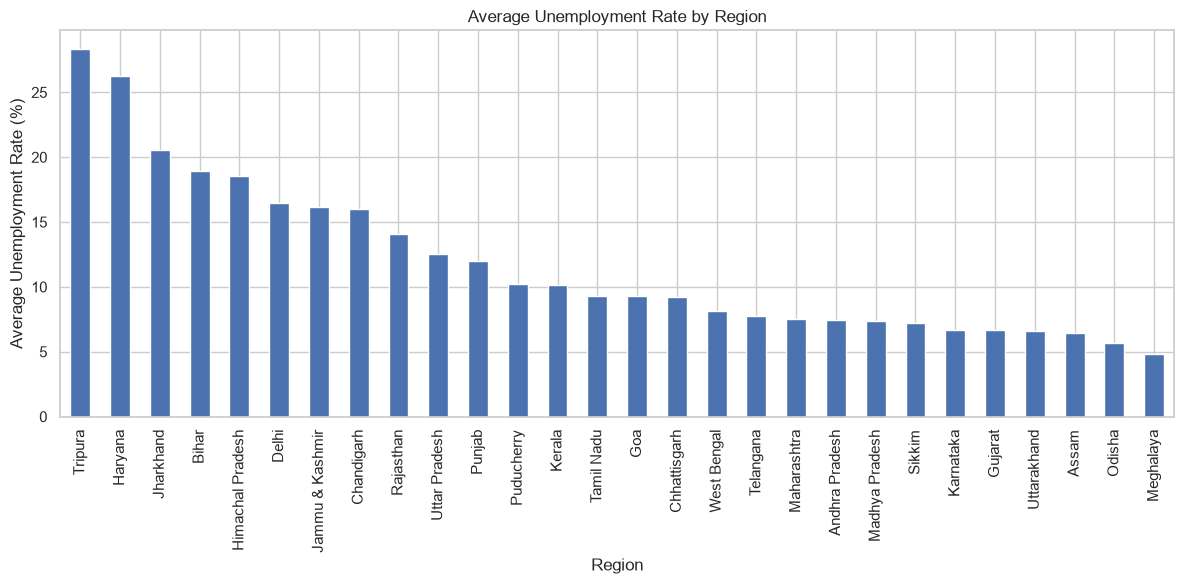

In [6]:
# Calculate the average unemployment rate for each region
region_unemployment = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

# Display the average unemployment rate by region
print("Average Unemployment Rate by Region:")
display(region_unemployment.round(2))

# Create a bar chart
plt.figure(figsize=(12, 6))
region_unemployment.plot(kind="bar")

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 3.2 Monthly Unemployment Trends

In this section, we analyze how the average unemployment rate changes over time by grouping the data by month and plotting the trend using a line chart.


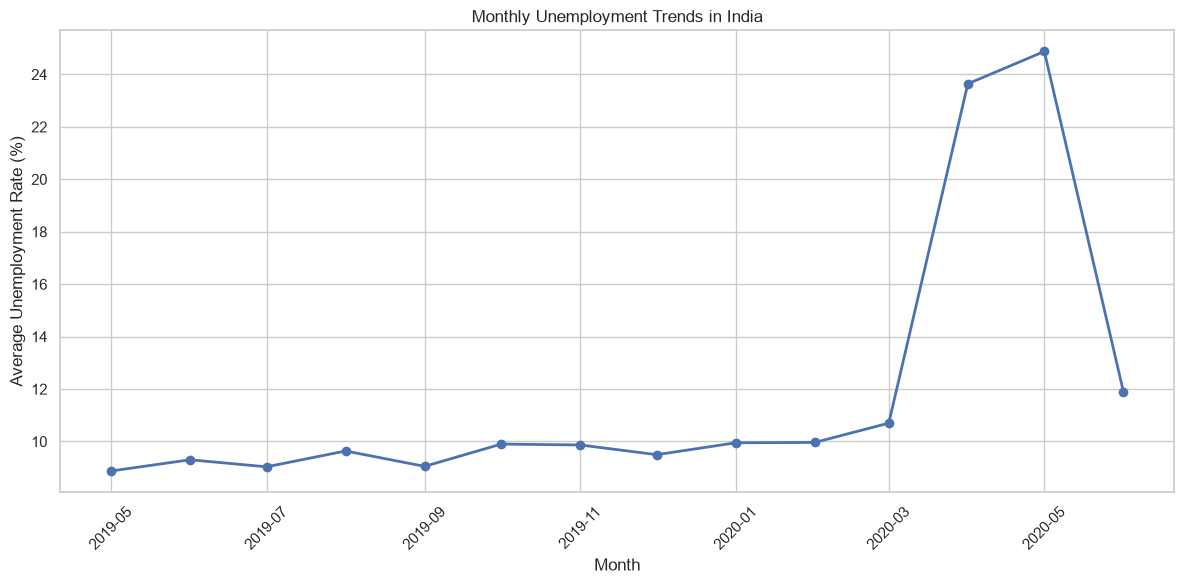

In [7]:
# Calculate the average unemployment rate for each month
monthly_unemployment = (
    df.groupby(df["Date"].dt.to_period("M"))[
        "Estimated Unemployment Rate (%)"
    ]
    .mean()
)

# Convert monthly periods into timestamps for plotting
monthly_unemployment.index = monthly_unemployment.index.to_timestamp()

# Create a line chart
plt.figure(figsize=(12, 6))
plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Unemployment Trends in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3.3 Unemployment Trends Across Selected States

In this section, we compare unemployment rates over time for selected Indian states using a line chart to understand how their trends differ.


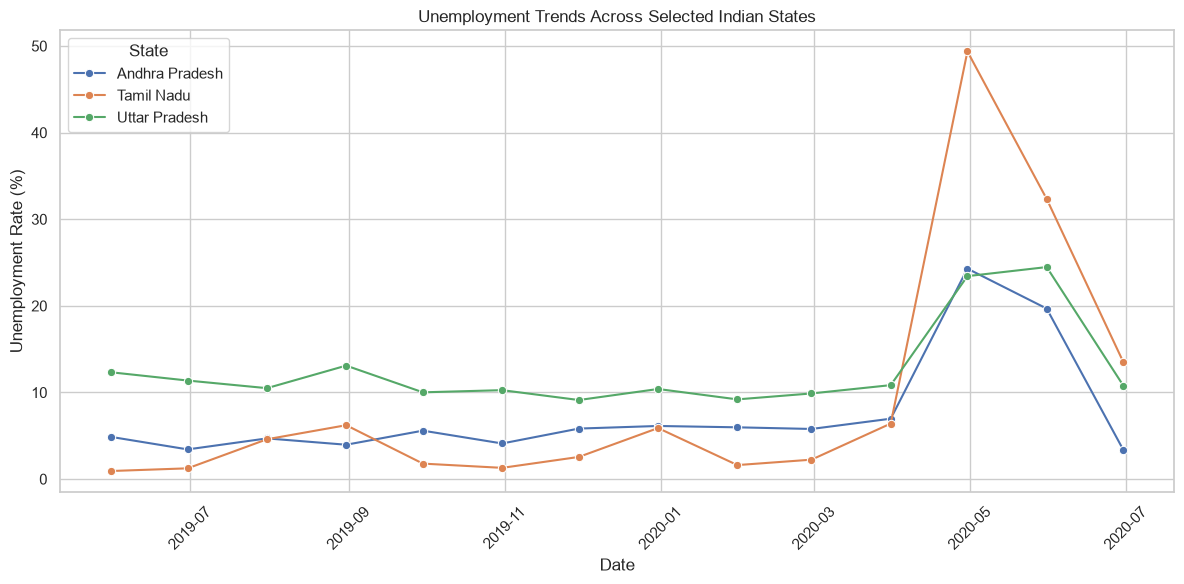

In [8]:
# Select three states for comparison
selected_states = ["Andhra Pradesh", "Tamil Nadu", "Uttar Pradesh"]

# Filter the dataset for the selected states
state_data = df[df["Region"].isin(selected_states)]

# Calculate the average unemployment rate for each state and date
state_trends = (
    state_data.groupby(["Date", "Region"])["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

# Create a line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=state_trends,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Region",
    marker="o"
)

plt.title("Unemployment Trends Across Selected Indian States")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="State")
plt.tight_layout()
plt.show()

## 3.4 Top 10 Regions by Average Unemployment Rate

In this section, we identify the ten regions with the highest average unemployment rates and visualize the results using a bar chart.


Top 10 Regions by Average Unemployment Rate:


Region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Delhi               16.50
Jammu & Kashmir     16.19
Chandigarh          15.99
Rajasthan           14.06
Uttar Pradesh       12.55
Name: Estimated Unemployment Rate (%), dtype: float64

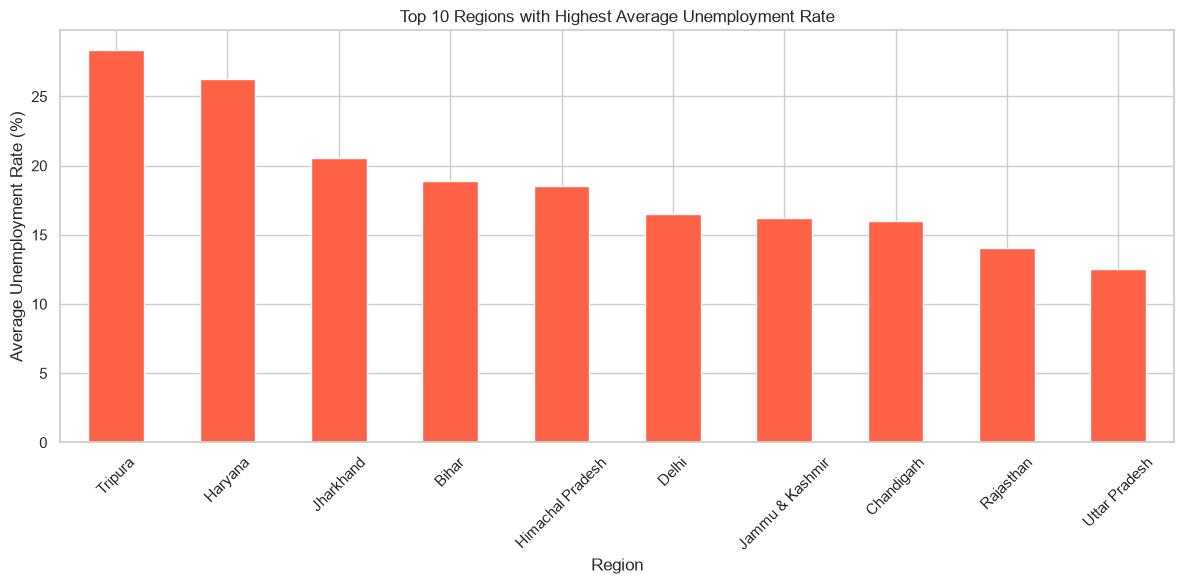

In [9]:
# Calculate the average unemployment rate for each region
average_unemployment = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

# Select the top 10 regions
top_10_regions = average_unemployment.head(10)

# Display the results
print("Top 10 Regions by Average Unemployment Rate:")
display(top_10_regions.round(2))

# Create a bar chart
plt.figure(figsize=(12, 6))
top_10_regions.plot(kind="bar", color="tomato")

plt.title("Top 10 Regions with Highest Average Unemployment Rate")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3.5 Correlation Between Employment Indicators

In this section, we examine the relationships between the unemployment rate, estimated employment, and labour participation rate using a correlation heatmap.


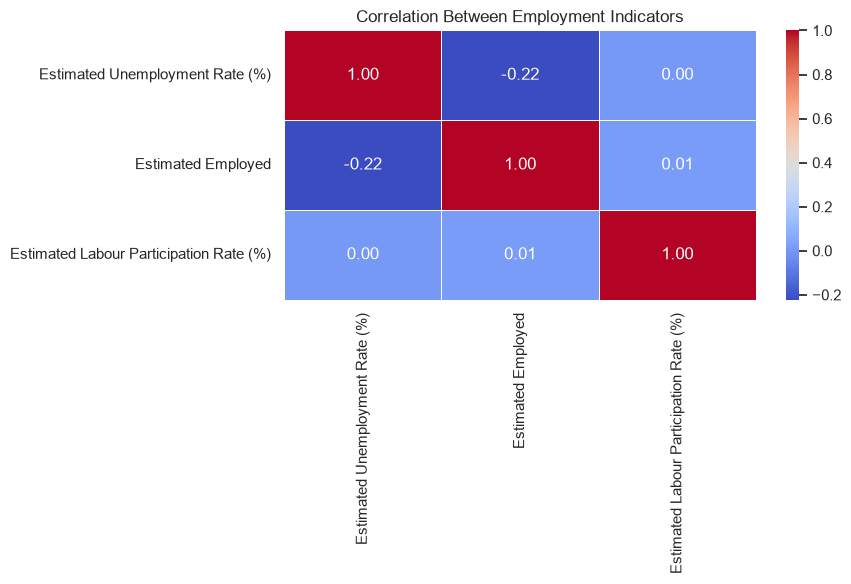

In [10]:
# Select the available numerical indicators
employment_indicators = df[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
]

# Calculate the correlation matrix
correlation_matrix = employment_indicators.corr()

# Create a correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Employment Indicators")
plt.tight_layout()
plt.show()

# 4. COVID-19 Impact Analysis

In this section, we compare average unemployment rates before and after March 2020 to examine how unemployment patterns changed around the onset of the COVID-19 pandemic.


In [11]:
# Define the COVID-19 comparison date
covid_start_date = pd.Timestamp("2020-03-01")

# Separate the data into pre-COVID and post-COVID periods
pre_covid = df[df["Date"] < covid_start_date]
post_covid = df[df["Date"] >= covid_start_date]

# Calculate average unemployment rates for both periods
pre_covid_rate = pre_covid["Estimated Unemployment Rate (%)"].mean()
post_covid_rate = post_covid["Estimated Unemployment Rate (%)"].mean()

# Display the results
print("Average Unemployment Rate Before March 2020:",
      round(pre_covid_rate, 2), "%")

print("Average Unemployment Rate From March 2020 Onward:",
      round(post_covid_rate, 2), "%")

print("Change in Average Unemployment Rate:",
      round(post_covid_rate - pre_covid_rate, 2), "percentage points")

Average Unemployment Rate Before March 2020: 9.51 %
Average Unemployment Rate From March 2020 Onward: 17.77 %
Change in Average Unemployment Rate: 8.26 percentage points


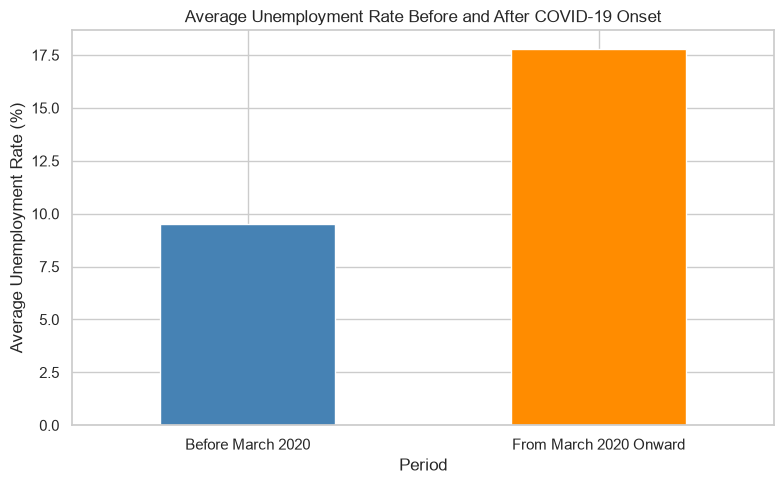

In [12]:
# Prepare data for visualization
covid_comparison = pd.Series(
    {
        "Before March 2020": pre_covid_rate,
        "From March 2020 Onward": post_covid_rate
    }
)

# Create a bar chart
plt.figure(figsize=(8, 5))
covid_comparison.plot(kind="bar", color=["steelblue", "darkorange"])

plt.title("Average Unemployment Rate Before and After COVID-19 Onset")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation

Compare the average unemployment rates before and from March 2020 onward. Identify whether the average rate increased or decreased and state the difference in percentage points based on the calculated results.

This comparison shows an association with the selected time periods; it does not establish that COVID-19 alone caused the change.


# 5. Key Findings and Conclusion

### Key Findings

* Regional unemployment averages reveal differences in unemployment levels across states and regions.
* Monthly trends help identify changes in unemployment over the observed period.
* Comparing selected states shows how unemployment patterns vary geographically.
* The correlation heatmap summarizes relationships between unemployment, estimated employment, and labour participation.
* The pre- and post-March 2020 comparison helps examine changes in unemployment around the onset of the COVID-19 pandemic.

### Conclusion

This analysis uses Python libraries such as Pandas, Matplotlib, and Seaborn to explore unemployment patterns in India. Data cleaning, statistical summaries, and visualizations help identify regional differences, temporal trends, and relationships between employment indicators. Comparing periods before and from March 2020 onward provides additional context for understanding unemployment during the pandemic period.
